# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Bima Satriawan | 5054251031 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)

Device yang digunakan: cpu


In [4]:
train_path = '/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv'
test_path = '/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv'

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Ukuran data train:", train_df.shape)
print("Ukuran data test:", test_df.shape)

Ukuran data train: (60000, 785)
Ukuran data test: (10000, 785)


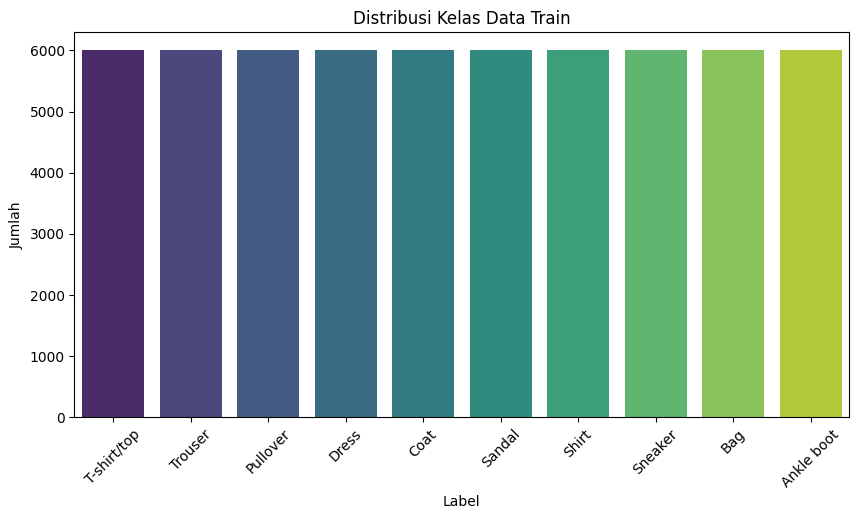

In [5]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 5))
sns.countplot(data=train_df, x='label', palette='viridis')
plt.title('Distribusi Kelas Data Train')
plt.xlabel('Label')
plt.ylabel('Jumlah')
plt.xticks(ticks=range(10), labels=class_names, rotation=45)
plt.show()

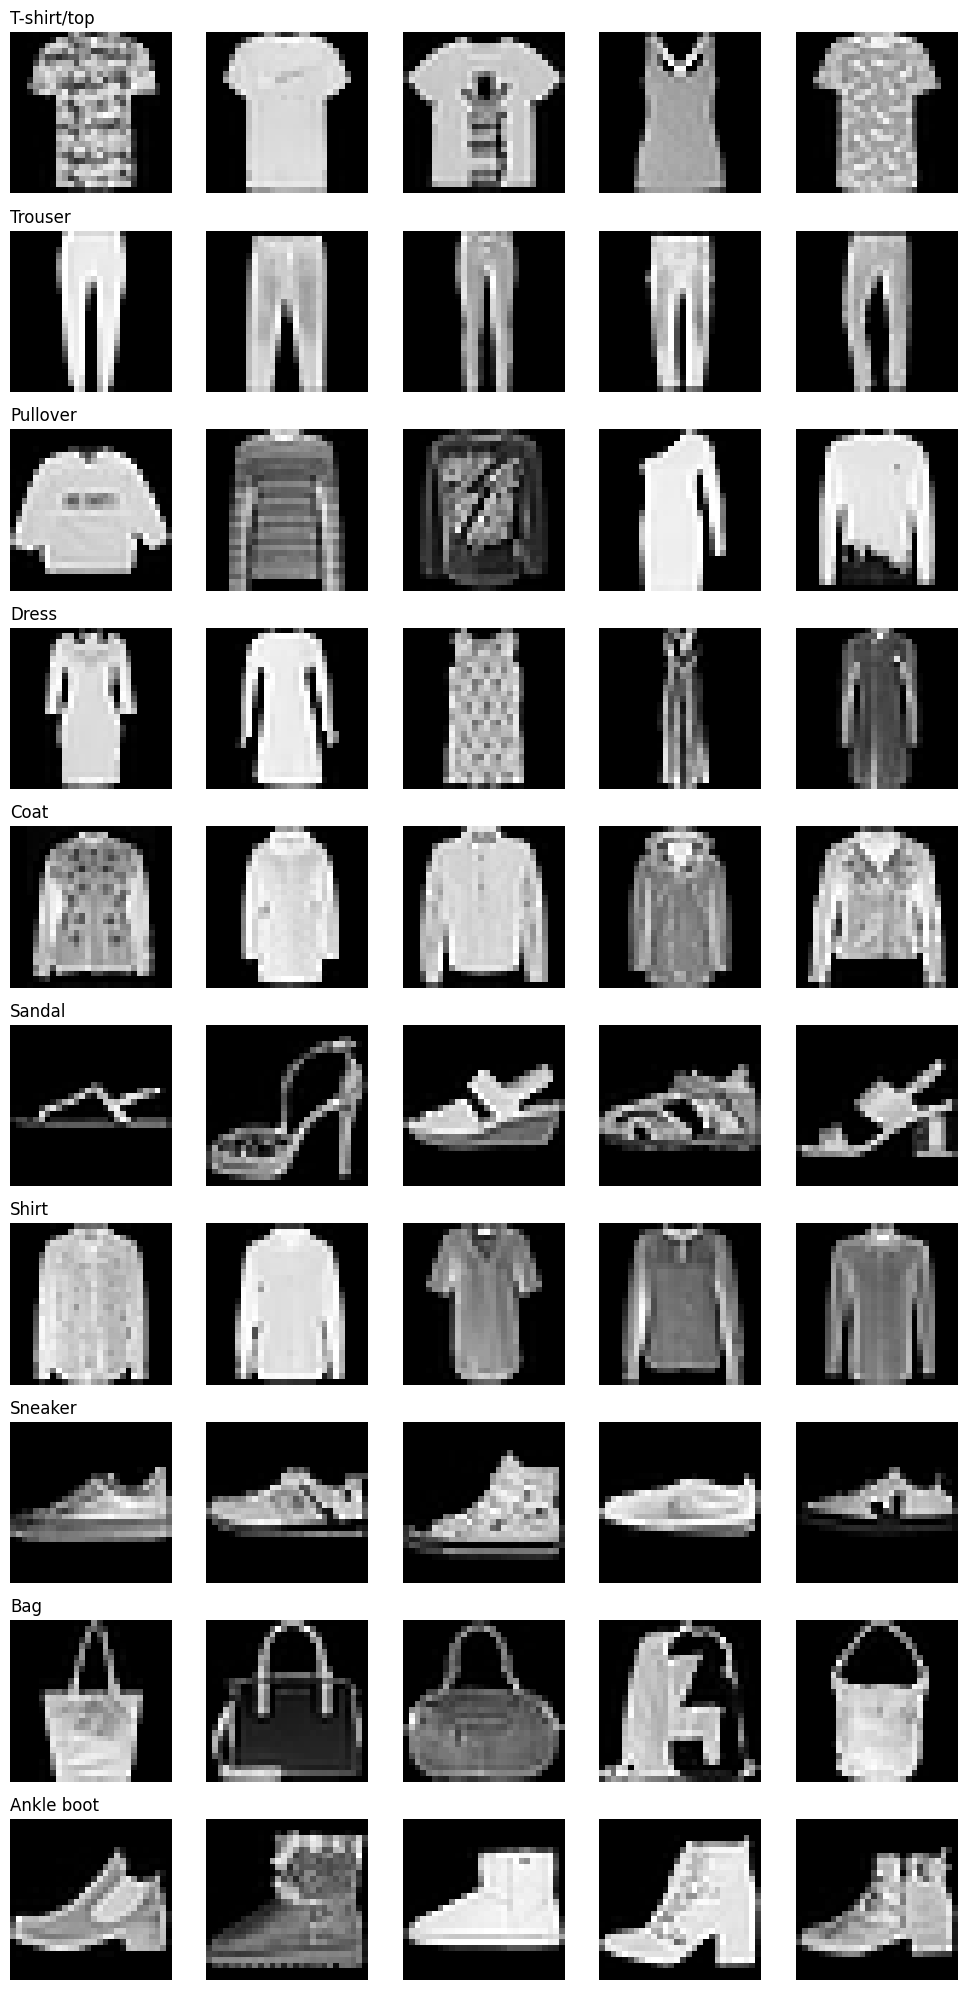

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(10, 20))
for i in range(10):
    class_df = train_df[train_df['label'] == i].iloc[:5]
    for j in range(5):
        img = class_df.iloc[j, 1:].values.reshape(28, 28)
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(class_names[i], loc='left', fontsize=12)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Berdasarkan eksplorasi awal, dataset Fashion-MNIST bersifat seimbang, dengan masing-masing kelas memiliki 6000 gambar pada train set dan 1000 gambar pada test set. Gambar memiliki resolusi 28x28 piksel grayscale.
Kesulitan utama dalam dataset ini adalah membedakan pakaian atas yang memiliki bentuk serupa seperti T-shirt/top, Shirt, Pullover, dan Coat. Jarak antar kelas dalam ruang piksel sangat dekat, sehingga model linear mungkin akan kesulitan membedakannya.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [7]:
X_train_full = train_df.drop('label', axis=1).values
y_train_full = train_df['label'].values
X_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

In [8]:
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

In [9]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full)

In [10]:
X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)
y_test_t = torch.tensor(y_test, dtype=torch.long)

batch_size = 64

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_t, y_val_t)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [11]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

model_ann = ANN().to(device)
print(model_ann)
print("Jumlah parameter:", sum(p.numel() for p in model_ann.parameters()))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [12]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * x_batch.size(0)
            _, predicted = torch.max(outputs, 1)
            train_correct += (predicted == y_batch).sum().item()
            train_total += y_batch.size(0)

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                outputs = model(x_batch)
                loss = criterion(outputs, y_batch)

                val_loss += loss.item() * x_batch.size(0)
                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == y_batch).sum().item()
                val_total += y_batch.size(0)

        history['train_loss'].append(train_loss / train_total)
        history['val_loss'].append(val_loss / val_total)
        history['train_acc'].append(train_correct / train_total)
        history['val_acc'].append(val_correct / val_total)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {history['train_loss'][-1]:.4f}, Train Acc: {history['train_acc'][-1]:.4f} - Val Loss: {history['val_loss'][-1]:.4f}, Val Acc: {history['val_acc'][-1]:.4f}")

    return history

criterion = nn.CrossEntropyLoss()
optimizer_ann = optim.Adam(model_ann.parameters(), lr=0.001)
history_ann = train_model(model_ann, train_loader, val_loader, criterion, optimizer_ann, epochs=10)

Epoch 1/10 - Train Loss: 0.5434, Train Acc: 0.8062 - Val Loss: 0.4427, Val Acc: 0.8393
Epoch 2/10 - Train Loss: 0.3825, Train Acc: 0.8593 - Val Loss: 0.3637, Val Acc: 0.8642
Epoch 3/10 - Train Loss: 0.3403, Train Acc: 0.8759 - Val Loss: 0.3599, Val Acc: 0.8700
Epoch 4/10 - Train Loss: 0.3176, Train Acc: 0.8831 - Val Loss: 0.3232, Val Acc: 0.8787
Epoch 5/10 - Train Loss: 0.2976, Train Acc: 0.8898 - Val Loss: 0.3296, Val Acc: 0.8790
Epoch 6/10 - Train Loss: 0.2818, Train Acc: 0.8952 - Val Loss: 0.3220, Val Acc: 0.8833
Epoch 7/10 - Train Loss: 0.2672, Train Acc: 0.9006 - Val Loss: 0.3193, Val Acc: 0.8865
Epoch 8/10 - Train Loss: 0.2553, Train Acc: 0.9045 - Val Loss: 0.3138, Val Acc: 0.8848
Epoch 9/10 - Train Loss: 0.2449, Train Acc: 0.9084 - Val Loss: 0.3186, Val Acc: 0.8835
Epoch 10/10 - Train Loss: 0.2345, Train Acc: 0.9107 - Val Loss: 0.3247, Val Acc: 0.8793


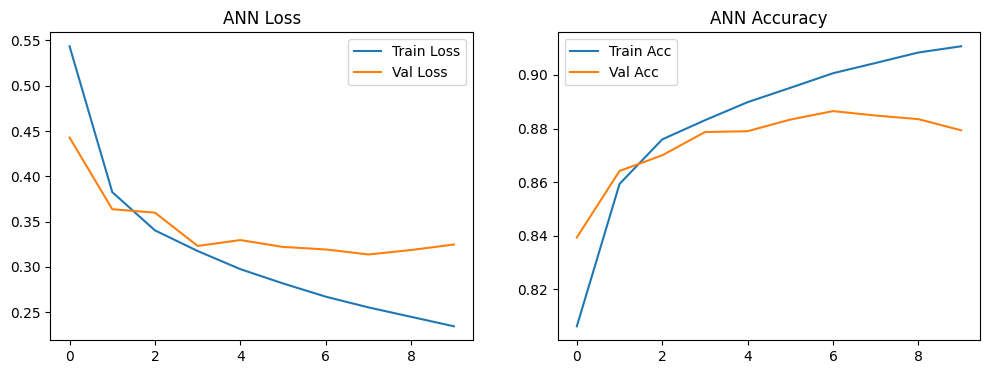

In [13]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'{title} Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train Acc')
    plt.plot(history['val_acc'], label='Val Acc')
    plt.title(f'{title} Accuracy')
    plt.legend()

    plt.show()

plot_history(history_ann, 'ANN')

In [14]:
model_ann.eval()
y_pred_ann = []
with torch.no_grad():
    for x_batch, _ in test_loader:
        x_batch = x_batch.to(device)
        outputs = model_ann(x_batch)
        _, predicted = torch.max(outputs, 1)
        y_pred_ann.extend(predicted.cpu().numpy())

y_pred_ann = np.array(y_pred_ann)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model_cnn = SimpleCNN().to(device)
print(model_cnn)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn.parameters()))

# Perhitungan manual:
# Input: 28x28
# Conv1 (padding=1, k=3): (28 - 3 + 2) / 1 + 1 = 28
# Pool1 (k=2): 28 / 2 = 14
# Conv2 (padding=1, k=3): (14 - 3 + 2) / 1 + 1 = 14
# Pool2 (k=2): 14 / 2 = 7
# Output akhir: 64 channel x 7 x 7 = 3136
dummy_input = torch.zeros(1, 1, 28, 28).to(device)
dummy_output = model_cnn.features(dummy_input)
print("Bentuk output konvolusi:", dummy_output.shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Bentuk output konvolusi: torch.Size([1, 64, 7, 7])


Epoch 1/10 - Train Loss: 0.4712, Train Acc: 0.8275 - Val Loss: 0.3284, Val Acc: 0.8778
Epoch 2/10 - Train Loss: 0.3003, Train Acc: 0.8927 - Val Loss: 0.2951, Val Acc: 0.8947
Epoch 3/10 - Train Loss: 0.2541, Train Acc: 0.9064 - Val Loss: 0.2795, Val Acc: 0.8972
Epoch 4/10 - Train Loss: 0.2198, Train Acc: 0.9191 - Val Loss: 0.2408, Val Acc: 0.9117
Epoch 5/10 - Train Loss: 0.1949, Train Acc: 0.9276 - Val Loss: 0.2388, Val Acc: 0.9117
Epoch 6/10 - Train Loss: 0.1744, Train Acc: 0.9361 - Val Loss: 0.2234, Val Acc: 0.9185
Epoch 7/10 - Train Loss: 0.1547, Train Acc: 0.9433 - Val Loss: 0.2196, Val Acc: 0.9220
Epoch 8/10 - Train Loss: 0.1358, Train Acc: 0.9503 - Val Loss: 0.2275, Val Acc: 0.9222
Epoch 9/10 - Train Loss: 0.1168, Train Acc: 0.9566 - Val Loss: 0.2233, Val Acc: 0.9222
Epoch 10/10 - Train Loss: 0.1022, Train Acc: 0.9621 - Val Loss: 0.2532, Val Acc: 0.9163


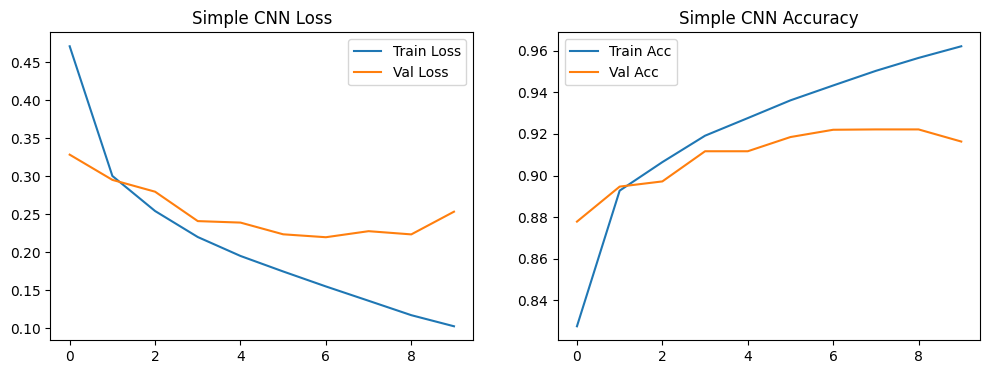

In [16]:
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)
history_cnn = train_model(model_cnn, train_loader, val_loader, criterion, optimizer_cnn, epochs=10)
plot_history(history_cnn, 'Simple CNN')

In [17]:
model_cnn.eval()
y_pred_cnn = []
with torch.no_grad():
    for x_batch, _ in test_loader:
        x_batch = x_batch.to(device)
        outputs = model_cnn(x_batch)
        _, predicted = torch.max(outputs, 1)
        y_pred_cnn.extend(predicted.cpu().numpy())

y_pred_cnn = np.array(y_pred_cnn)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [18]:
class CNNBN(nn.Module):
    def __init__(self):
        super(CNNBN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model_cnn_bn = CNNBN().to(device)
print(model_cnn_bn)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn_bn.parameters()))

CNNBN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch 1/10 - Train Loss: 0.5329, Train Acc: 0.8074 - Val Loss: 0.3184, Val Acc: 0.8828
Epoch 2/10 - Train Loss: 0.3689, Train Acc: 0.8689 - Val Loss: 0.2820, Val Acc: 0.9018
Epoch 3/10 - Train Loss: 0.3230, Train Acc: 0.8843 - Val Loss: 0.2554, Val Acc: 0.9083
Epoch 4/10 - Train Loss: 0.2942, Train Acc: 0.8951 - Val Loss: 0.2514, Val Acc: 0.9093
Epoch 5/10 - Train Loss: 0.2672, Train Acc: 0.9030 - Val Loss: 0.2334, Val Acc: 0.9220
Epoch 6/10 - Train Loss: 0.2536, Train Acc: 0.9085 - Val Loss: 0.2356, Val Acc: 0.9160
Epoch 7/10 - Train Loss: 0.2351, Train Acc: 0.9149 - Val Loss: 0.2295, Val Acc: 0.9202
Epoch 8/10 - Train Loss: 0.2248, Train Acc: 0.9182 - Val Loss: 0.2375, Val Acc: 0.9177
Epoch 9/10 - Train Loss: 0.2102, Train Acc: 0.9235 - Val Loss: 0.2283, Val Acc: 0.9173
Epoch 10/10 - Train Loss: 0.1974, Train Acc: 0.9285 - Val Loss: 0.2423, Val Acc: 0.9147


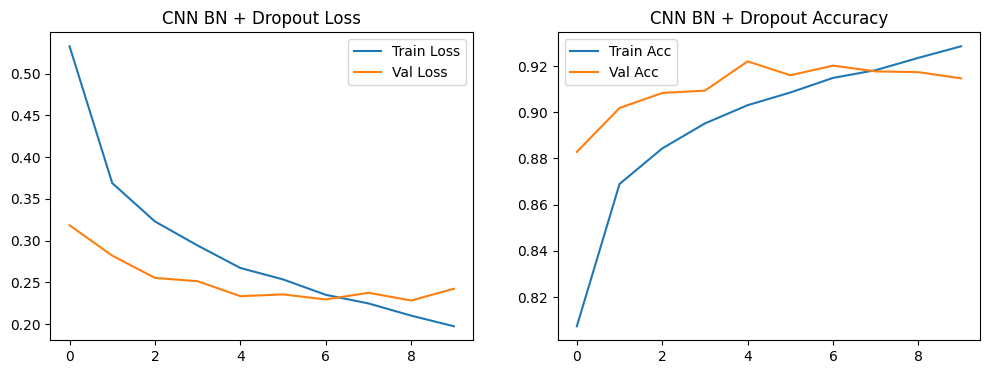

In [19]:
optimizer_cnn_bn = optim.Adam(model_cnn_bn.parameters(), lr=0.001)
history_cnn_bn = train_model(model_cnn_bn, train_loader, val_loader, criterion, optimizer_cnn_bn, epochs=10)
plot_history(history_cnn_bn, 'CNN BN + Dropout')

In [20]:
model_cnn_bn.eval()
y_pred_cnn_bn = []
with torch.no_grad():
    for x_batch, _ in test_loader:
        x_batch = x_batch.to(device)
        outputs = model_cnn_bn(x_batch)
        _, predicted = torch.max(outputs, 1)
        y_pred_cnn_bn.extend(predicted.cpu().numpy())

y_pred_cnn_bn = np.array(y_pred_cnn_bn)

# 4. Evaluasi Model

In [28]:
models_dict = {
    'ANN': (y_pred_ann, model_ann),
    'Simple CNN': (y_pred_cnn, model_cnn),
    'CNN BN + Dropout': (y_pred_cnn_bn, model_cnn_bn)
}

metrics_list = []
for name, (preds, model) in models_dict.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='macro')
    rec = recall_score(y_test, preds, average='macro')
    f1 = f1_score(y_test, preds, average='macro')
    params = sum(p.numel() for p in model.parameters())

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Macro)': prec,
        'Recall (Macro)': rec,
        'F1-Score (Macro)': f1,
        'Jumlah Parameter': params
    })

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Jumlah Parameter
0,ANN,0.8842,0.887449,0.8842,0.883072,235146
1,Simple CNN,0.9241,0.929417,0.9241,0.925274,421642
2,CNN BN + Dropout,0.9224,0.924367,0.9224,0.922270,421834


In [22]:
best_model_name = 'CNN BN + Dropout'
best_preds = y_pred_cnn_bn

print(f"Classification Report untuk {best_model_name}:")
print(classification_report(y_test, best_preds, target_names=class_names))

Classification Report untuk CNN BN + Dropout:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.89      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.95      0.81      0.87      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.83      0.94      0.88      1000
      Sandal       1.00      0.97      0.98      1000
       Shirt       0.78      0.77      0.78      1000
     Sneaker       0.92      0.99      0.95      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.99      0.95      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



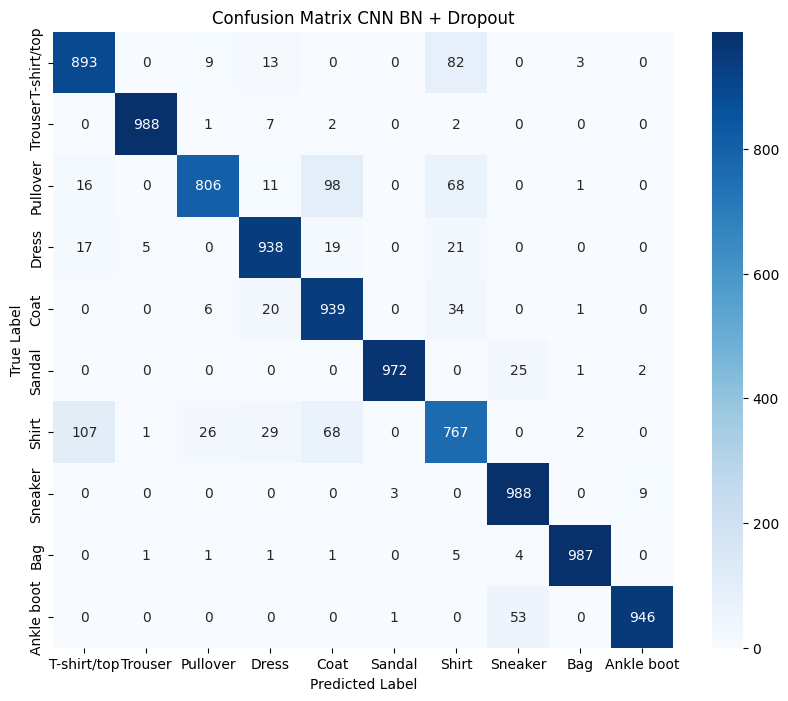

In [23]:
cm = confusion_matrix(y_test, y_pred_cnn_bn)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix CNN BN + Dropout')
plt.show()

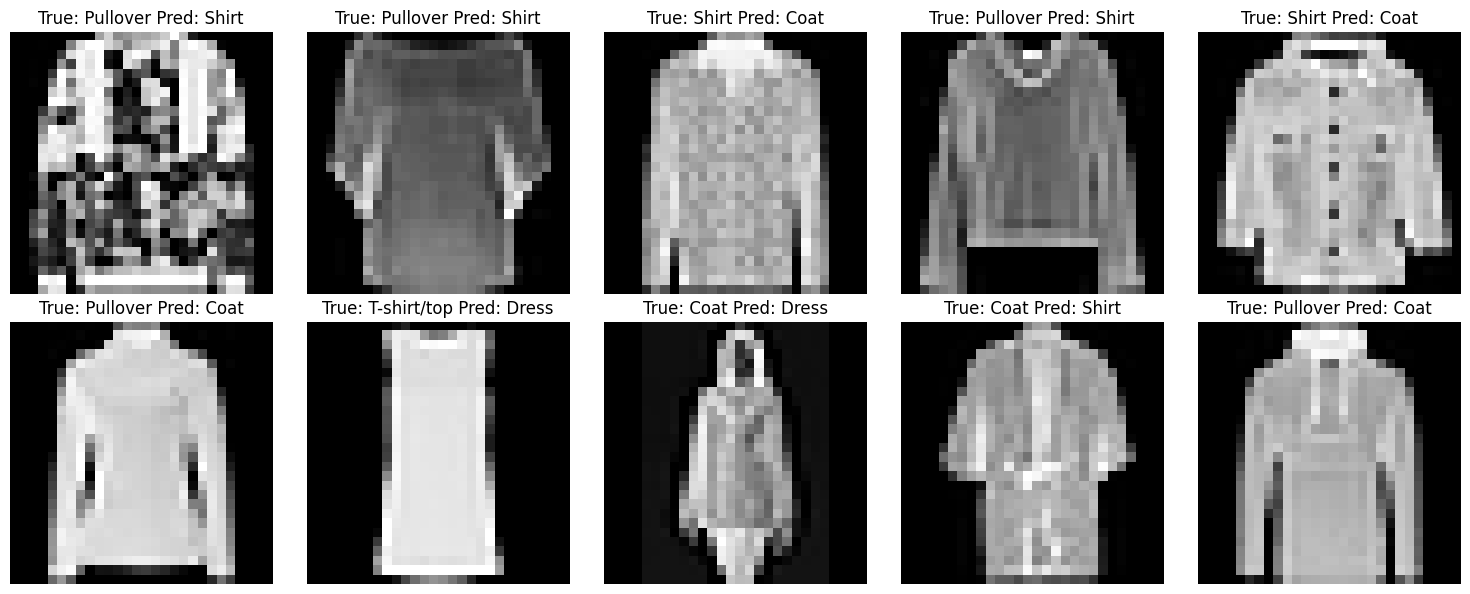

In [24]:
misclassified_idx = np.where(y_test != y_pred_cnn_bn)[0]

plt.figure(figsize=(15, 6))
for i, idx in enumerate(misclassified_idx[:10]):
    plt.subplot(2, 5, i + 1)
    img = X_test[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {class_names[y_test[idx]]} Pred: {class_names[y_pred_cnn_bn[idx]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

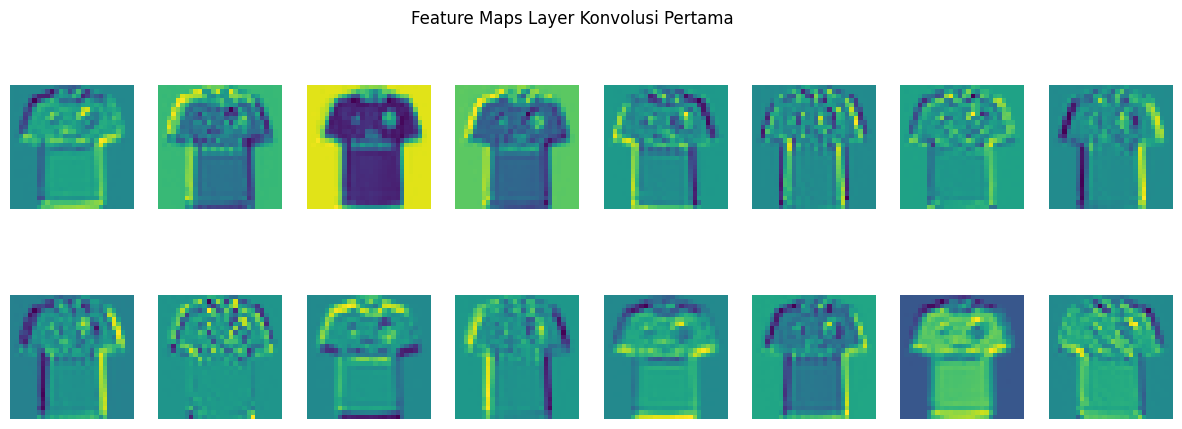

In [25]:
model_cnn_bn.eval()
sample_idx = 0
sample_img = X_test_t[sample_idx].unsqueeze(0).to(device)

with torch.no_grad():
    feature_maps = model_cnn_bn.features[0](sample_img)

feature_maps = feature_maps.cpu().numpy()[0]

plt.figure(figsize=(15, 5))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(feature_maps[i], cmap='viridis')
    plt.axis('off')
plt.suptitle('Feature Maps Layer Konvolusi Pertama')
plt.show()

In [26]:
torch.save(model_cnn_bn.state_dict(), "model.pth")
print("Model berhasil disimpan sebagai model.pth")

class CNNBN(nn.Module):
    def __init__(self):
        super(CNNBN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

Model berhasil disimpan sebagai model.pth


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Berdasarkan hasil eksperimen, terdapat perbedaan performa yang sangat mencolok antara ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.

1. ANN Baseline: Model ini memiliki akurasi terendah. Meskipun memiliki jumlah parameter yang besar karena layer fully connected, ANN tidak dapat menangkap informasi spasial dari gambar. Gambar yang di-flatten menjadi vektor kehilangan hubungan antar piksel yang bertetangga, sehingga model kesulitan mengenali pola bentuk pakaian.
2. CNN Sederhana: Performa CNN sederhana jauh melampaui ANN. CNN memanfaatkan operasi konvolusi untuk mengekstrak fitur lokal seperti tepi dan tekstur, serta mempertahankan struktur spasial gambar. Dengan jumlah parameter yang jauh lebih sedikit, CNN mampu mencapai akurasi yang jauh lebih tinggi. Namun, learning curve menunjukkan adanya sedikit jarak antara train dan validation accuracy yang mengindikasikan awal mula overfitting.
3. CNN dengan Batch Normalization dan Dropout: Model ini memberikan performa terbaik. Penambahan Batch Normalization membantu menstabilkan dan mempercepat proses training, sedangkan Dropout mencegah model terlalu menghafal data train. Learning curve-nya menunjukkan selisih yang lebih kecil antara train dan validation dibandingkan CNN sederhana, yang berarti model lebih generalis.

Kelas-kelas yang paling sulit dibedakan oleh model adalah pakaian atas (upper garments) seperti Shirt, T-shirt/top, Pullover, dan Coat. Hal ini terlihat dari Confusion Matrix di mana Shirt sering diprediksi sebagai T-shirt/top atau Pullover. Secara visual, bentuk dasar pakaian-pakaian tersebut memang sangat mirip pada resolusi 28x28.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Kesimpulan:
1. CNN terbukti jauh lebih unggul dibandingkan ANN biasa untuk tugas klasifikasi gambar seperti Fashion-MNIST. CNN mampu mengekstrak fitur spasial secara otomatis melalui operasi konvolusi, yang tidak bisa dilakukan oleh ANN yang hanya bekerja pada data tabular (vektor yang di-flatten).
2. Penambahan teknik regularisasi seperti Batch Normalization dan Dropout pada CNN sangat efektif untuk meningkatkan performa model, mempercepat konvergensi, dan menekan overfitting.
3. Kesulitan utama pada dataset ini terletak pada kemiripan visual antar kelas pakaian atas (Shirt, T-shirt/top, Pullover, Coat).

Saran:
Untuk eksperimen selanjutnya, dapat dicoba penggunaan arsitektur CNN yang lebih modern seperti ResNet atau VGG yang disesuaikan untuk gambar 28x28, atau menggunakan teknik Data Augmentation (seperti rotasi kecil atau pergeseran) untuk menambah variasi data train.
